# 03 · Free-space propagation and Gaussian diffraction: build it step by step

A paraxial field changes as it travels. The Fresnel transfer-function method evolves every spatial-frequency component by a distance-dependent phase, letting us follow beam width and intensity.

This companion develops the same idea with small functions defined beside the experiment that needs them.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


## 1. Put the paraxial transfer function in a function

For each spatial frequency, free-space propagation multiplies the spectrum by a quadratic phase. The function keeps the grid convention and FFT bookkeeping together.

In [ ]:
def propTF(field, window_m, wavelength_m, z_m):
    """Fresnel-propagate a 1D complex field by z_m."""
    n = field.size
    dx = window_m / n
    freq = np.fft.fftshift(np.fft.fftfreq(n, d=dx))
    transfer = np.exp(-1j * np.pi * wavelength_m * z_m * freq**2)
    spectrum = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(field)))
    return np.fft.fftshift(np.fft.ifft(np.fft.ifftshift(spectrum * transfer)))

lambda_m = 500e-9
window_m = 4e-3
n = 2048
x_m = np.linspace(-window_m/2, window_m/2, n, endpoint=False)
sigma_m = 100e-6
field0 = np.exp(-x_m**2/(4*sigma_m**2))


## 2. Use the propagation function

The helper now contains the Fourier-domain calculation. We can focus on what the field does at a chosen plane.

In [ ]:
z_m = 0.20
field_z = propagate(field0, window_m, lambda_m, z_m)


## 3. Define the RMS measurement in the same physical context

The width of a propagated field is its intensity-weighted spatial standard deviation. Define it here so the simulated beam evolution is self-contained.

In [ ]:
def rms_width(field, x):
    """Intensity-weighted RMS width, in the units of x."""
    intensity = np.abs(field)**2
    weights = intensity / intensity.sum()
    center = np.sum(weights*x)
    return np.sqrt(np.sum(weights*(x-center)**2))

z_values_m = np.linspace(0, 0.4, 41)
widths_m = np.array([rms_width(propTF(field0, window_m, lambda_m, z), x_m) for z in z_values_m])


## Original plot code (verbatim)

The following code cells and saved outputs are copied unchanged from the cited notebook cells. Some source cells rely on variables established earlier in their original notebook.


From `paper/03_FourierPropagation.ipynb`, cell 28.


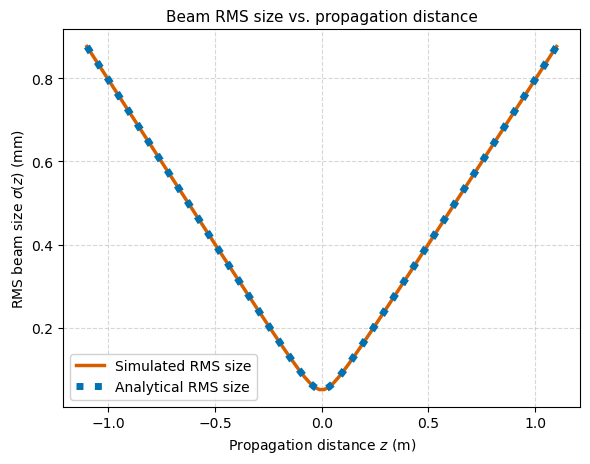

In [13]:
plt.figure(figsize=FIG_SIZE)

# High-contrast solid line for simulation
plt.plot(Z_m, np.array(sim_beam_sizes_m) * 1e3,
         label='Simulated RMS size', color='#D55E00', linewidth=2.5)

# High-contrast dashed line for analytical model
plt.plot(Z_m, np.array(sigma_th_m) * 1e3,
         ':', label='Analytical RMS size', color='#0072B2', linewidth=5)

plt.xlabel('Propagation distance $z$ (m)', fontsize=10)
plt.ylabel('RMS beam size $\\sigma(z)$ (mm)', fontsize=10)
plt.title('Beam RMS size vs. propagation distance', fontsize=11)
plt.grid(True, ls='--', alpha=0.5)
plt.legend(framealpha=0.9)
plt.tight_layout()
plt.show()

From `paper/03_FourierPropagation.ipynb`, cell 30.


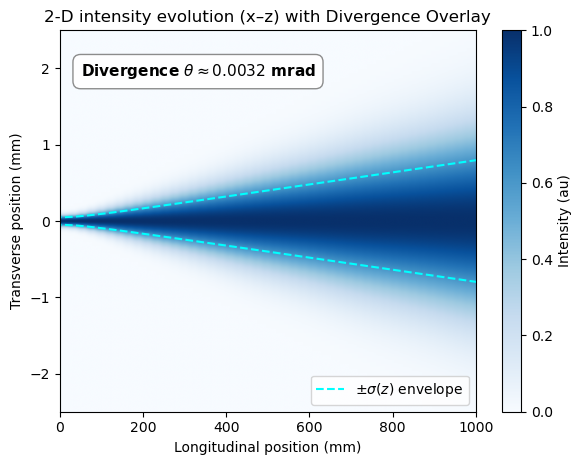

In [45]:
# --- Plot 2: 2D Intensity Evolution with Beam Envelope & Theta ---
plt.figure(figsize=FIG_SIZE)

# Extent y-limits scaled by 1e3 to convert x_m bounds to mm
im = plt.imshow(np.transpose(Ixz),
                extent=[Z_m[0]*1e3, Z_m[-1]*1e3, x_m[0]*1e3, x_m[-1]*1e3],
                aspect='auto',
                cmap='Blues')

valid_indices = np . abs ( Z_m ) > 0.5
z_far = Z_m [ valid_indices ]
sigma_far = sim_beam_sizes_m [ valid_indices ]
# Perform a 1 st - degree polynomial ( linear ) least - squares fit :
# sigma ( z ) = slope * z + intercept
popt , cov = np . polyfit ( z_far , sigma_far , 1 , cov = True )
# The slope ( first element ) corresponds to the numerical divergence angle
theta_measured = popt [0]

# Overlay RMS beam size envelope lines (± sigma(z)) in mm
plt.plot(Z_m * 1e3, sim_beam_sizes_m * 1e3, color='cyan', linestyle='--', linewidth=1.5, label=r'$\pm \sigma(z)$ envelope')
plt.plot(Z_m * 1e3, -sim_beam_sizes_m * 1e3, color='cyan', linestyle='--', linewidth=1.5)

# Annotate measured theta on the figure
plt.text(
    0.05, 0.88, 
    r'Divergence $\theta \approx {:.4f}$ mrad'.format(theta_measured * 1e3), 
    transform=plt.gca().transAxes,
    fontsize=11, 
    fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.9)
)

plt.ylim([-2.5, 2.5])  # Bounds in mm (-2.5 mm to 2.5 mm)
plt.xlabel("Longitudinal position (mm)")
plt.ylabel("Transverse position (mm)")
plt.xlim([0, 1000])
plt.title("2-D intensity evolution (x–z) with Divergence Overlay")
plt.colorbar(im, label='Intensity (au)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()